# Visible-Prefix Self-Validation + TVT+Z Projection

Eğitilmiş typewell-attention modelinin (`sequence_based_with_typewell.ipynb`) tahminleri üzerine iki post-processing tekniği uygular. İkisi de public-frontier Kaggle notebook'undan uyarlandı ve **hedef görmeden** çalışır — inference anında da uygulanabilir.

## 1. TVT+Z projection

TVT tek başına gürültülüdür ama stratigrafik seviye \(U_i = TVT_i + Z_i\) (formasyon düzlemi) MD boyunca pürüzsüzdür. Normalize MD \(s_i\) üzerinde robust düşük dereceli polinom fit edilir ve tahmin bu düzleştirilmiş seviyeye doğru çekilir:

$$\hat U_i = f_d(s_i), \qquad T_i^{proj} = (1-\lambda)\,T_i^{pred} + \lambda\,(\hat U_i - Z_i)$$

\(\lambda\) (çekme gücü) ve \(d\) (polinom derecesi) aday hiperparametrelerdir.

## 2. Visible-prefix self-validation

Hangi \((\lambda, d)\) adayının (veya ham tahminin) daha iyi olduğu kuyudan kuyuya değişir. Seçim için bilinen prefix'in kuyruğu gizlenir: gerçek PS'in %50/%65/%75'ine sentetik bir cut konur, model oradan tahmin eder ve adaylar **gizlenen ama bilinen** bölgede (cut → gerçek PS) RMSE ile sıralanır. Kuyu başına kazanan aday, gerçek PS tahminine uygulanır.

Bu seçim yalnızca inference anında görünür veriyi kullandığı için leakage içermez.

**Önkoşul:** `typewell_attn_best.pt` checkpoint'i. Eğitim notebook'unun son hücresi artık bunu kaydediyor; hâlâ açık bir eğitim oturumun varsa yeniden eğitmeden `torch.save(model.state_dict(), "typewell_attn_best.pt")` çalıştırman yeterli.

In [1]:
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

from training import (
    RNN_DROP_COLUMNS,
    RNN_FEATURE_COLUMNS,
    StatefulTVTWindowDataset,
    prepare_rnn_features,
)
from utils import (
    get_all_test_ids,
    get_all_training_ids,
    test_folder,
    train_folder,
)

# Egitim notebook'uyla birebir ayni olmali: split ve scaler'lar ayni
# train kuyularindan uretilmezse checkpoint'in gordugu dagilim bozulur.
SEED = 42
VALID_SIZE = 0.15
WINDOW_SIZE = 256
CONTEXT_LENGTH = 256

CHECKPOINT_PATH = "typewell_attn_best.pt"

# Self-validation ayarlari
CUT_FRACTIONS = (0.50, 0.65, 0.75)   # gercek PS'in bu oranlarina cut konur
MIN_CUT_EVAL_ROWS = 64               # cut ile PS arasi en az bu kadar satir

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

all_training_ids = get_all_training_ids()
reserved_test_ids = set(get_all_test_ids())
modeling_ids = sorted(set(all_training_ids) - reserved_test_ids)

train_well_ids, valid_well_ids = train_test_split(
    modeling_ids,
    test_size=VALID_SIZE,
    random_state=SEED,
    shuffle=True,
)

train_wells = prepare_rnn_features(
    training_ids=train_well_ids,
    feature_columns=RNN_FEATURE_COLUMNS,
    drop_columns=RNN_DROP_COLUMNS,
    imputed=True,
)
valid_wells = prepare_rnn_features(
    training_ids=valid_well_ids,
    feature_columns=RNN_FEATURE_COLUMNS,
    drop_columns=RNN_DROP_COLUMNS,
    imputed=True,
)
test_wells = prepare_rnn_features(
    training_ids=sorted(reserved_test_ids),
    feature_columns=RNN_FEATURE_COLUMNS,
    drop_columns=RNN_DROP_COLUMNS,
    imputed=True,
    data_dir=test_folder,
    target_data_dir=train_folder,
)
len(train_wells), len(valid_wells), len(test_wells)

/Users/doruksarigun/Kaggle/ROGII - Wellbore Geology Prediction/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: mps


(654, 116, 3)

In [2]:
# Typewell bellegi + scaler'lar — egitim notebook'undaki pipeline'in
# birebir kopyasi. Checkpoint bu tokenlar ve olceklerle egitildi.

TYPEWELL_GRID_POINTS = 512
TYPEWELL_TOKEN_HALF_WINDOW = 6  # token = 13 komsu GR + dtvt


def build_typewell_grid(typewell_df, num_points=TYPEWELL_GRID_POINTS):
    typewell = (
        typewell_df.dropna(subset=["TVT", "GR"])
        .sort_values("TVT")
        .drop_duplicates("TVT")
    )
    if len(typewell) < 2:
        raise ValueError("Typewell icinde yeterli TVT-GR verisi yok.")
    tvt_grid = np.linspace(
        typewell["TVT"].min(), typewell["TVT"].max(), num_points
    ).astype(np.float32)
    gr_grid = np.interp(
        tvt_grid,
        typewell["TVT"].to_numpy(dtype=float),
        typewell["GR"].to_numpy(dtype=float),
    ).astype(np.float32)
    return tvt_grid, gr_grid


def fit_typewell_gr_calibration(known_tvt, known_gr, tvt_grid, gr_grid):
    in_range = (known_tvt >= tvt_grid[0]) & (known_tvt <= tvt_grid[-1])
    known_tvt = known_tvt[in_range]
    known_gr = known_gr[in_range]
    if len(known_tvt) < 3:
        return 1.0, 0.0
    expected_gr = np.interp(known_tvt, tvt_grid, gr_grid)
    scale, offset = np.polyfit(expected_gr, known_gr, 1)
    if not np.isfinite(scale) or abs(scale) < 1e-8:
        return 1.0, 0.0
    return float(scale), float(offset)


def known_calibration_pairs(well_data, tvt_column, gr_column="GR"):
    known = well_data.loc[
        well_data[tvt_column].notna() & (well_data["GR_isna"] == 0),
        [tvt_column, gr_column],
    ]
    return (
        known[tvt_column].to_numpy(dtype=float),
        known[gr_column].to_numpy(dtype=float),
    )


def build_typewell_gr_tokens(gr_grid, half_window=TYPEWELL_TOKEN_HALF_WINDOW):
    padded = np.pad(gr_grid, half_window, mode="edge")
    return np.lib.stride_tricks.sliding_window_view(
        padded, 2 * half_window + 1
    ).astype(np.float32)


def attach_typewell_memory(prepared_wells):
    for well in tqdm(prepared_wells.values(), desc="Typewell memory", unit="well"):
        tvt_grid, gr_grid = build_typewell_grid(well.typewell_df)
        known_tvt, known_gr = known_calibration_pairs(
            well.data, "observed_TVT"
        )
        scale, offset = fit_typewell_gr_calibration(
            known_tvt, known_gr, tvt_grid, gr_grid
        )
        well.tw_tvt_grid = tvt_grid
        well.tw_gr_grid = gr_grid
        well.tw_gr_tokens_raw = build_typewell_gr_tokens(gr_grid)
        well.tw_gr_tokens = well.tw_gr_tokens_raw * scale + offset
        well.tw_gr_calibration = (scale, offset)


attach_typewell_memory(train_wells)
attach_typewell_memory(valid_wells)
attach_typewell_memory(test_wells)

MASK_FEATURE_COLUMNS = [
    "GR_isna",
    "GR_typewell_imputed_mask",
    "GR_neighbor_imputed_mask",
]
CONTINUOUS_FEATURE_COLUMNS = [
    column for column in RNN_FEATURE_COLUMNS
    if column not in MASK_FEATURE_COLUMNS
]

feature_scaler = StandardScaler()
target_scaler = StandardScaler()
for well in train_wells.values():
    feature_scaler.partial_fit(well.data[CONTINUOUS_FEATURE_COLUMNS])
    target_scaler.partial_fit(well.data[["TVT"]])

target_mean = float(target_scaler.mean_[0])
target_scale = float(target_scaler.scale_[0])
_gr_channel = CONTINUOUS_FEATURE_COLUMNS.index("GR")
gr_mean = float(feature_scaler.mean_[_gr_channel])
gr_scale = float(feature_scaler.scale_[_gr_channel])


def apply_scalers(prepared_wells):
    for well in prepared_wells.values():
        # Ham kopyalar: GR_raw episode kalibrasyonu icin, Z_raw ve MD_raw
        # TVT+Z projection icin (feature kolonlari scaler'dan gecer).
        well.data.loc[:, "GR_raw"] = well.data["GR"]
        well.data.loc[:, "Z_raw"] = well.data["Z"]
        well.data.loc[:, "MD_raw"] = well.data["MD"]
        well.data.loc[:, CONTINUOUS_FEATURE_COLUMNS] = (
            feature_scaler.transform(well.data[CONTINUOUS_FEATURE_COLUMNS])
        )
        well.data.loc[:, "TVT_scaled"] = target_scaler.transform(
            well.data[["TVT"]]
        ).ravel()
        well.data.loc[:, "observed_TVT_scaled"] = 0.0
        observed_mask = well.data["observed_TVT"].notna()
        well.data.loc[observed_mask, "observed_TVT_scaled"] = (
            well.data.loc[observed_mask, "observed_TVT"] - target_mean
        ) / target_scale
        well.tw_gr_tokens_scaled = (
            (well.tw_gr_tokens - gr_mean) / gr_scale
        ).astype(np.float32)


apply_scalers(train_wells)
apply_scalers(valid_wells)
apply_scalers(test_wells)
print(f"target: mean={target_mean:.1f}, scale={target_scale:.1f}")

Typewell memory: 100%|██████████| 3/3 [00:00<00:00, 925.08well/s]


target: mean=11502.7, scale=637.7


In [3]:
# Dataset ve model siniflari (egitim notebook'uyla ayni) + checkpoint yukleme.


class TypewellStatefulTVTWindowDataset(StatefulTVTWindowDataset):
    def __init__(
        self,
        *,
        tw_tvt_grid,
        tw_gr_tokens_scaled,
        target_scale,
        target_mean,
        **kwargs,
    ):
        super().__init__(**kwargs)
        anchor_row = self.prediction_start - 1
        anchor_tvt = float(self.data.loc[anchor_row, "TVT"])
        dtvt = (
            (tw_tvt_grid.astype(np.float64) - anchor_tvt) / target_scale
        ).astype(np.float32)
        self.anchor_tvt = anchor_tvt
        self.anchor_scaled = torch.tensor(
            (anchor_tvt - target_mean) / target_scale, dtype=torch.float32
        )
        self.tw_dtvt = torch.from_numpy(dtvt)
        self.tw_tokens = torch.from_numpy(
            np.concatenate(
                [tw_gr_tokens_scaled, dtvt[:, None]], axis=1
            ).astype(np.float32)
        )

    def __getitem__(self, idx):
        item = super().__getitem__(idx)
        item["tw_tokens"] = self.tw_tokens
        item["tw_dtvt"] = self.tw_dtvt
        item["anchor_scaled"] = self.anchor_scaled
        return item


def make_real_dataset(well):
    """Gercek PS'li dataset; kuyu bazli (gercek prefix) kalibrasyon."""
    return TypewellStatefulTVTWindowDataset(
        data=well.data,
        feature_columns=RNN_FEATURE_COLUMNS,
        target_column="TVT_scaled",
        window_size=WINDOW_SIZE,
        context_length=CONTEXT_LENGTH,
        mode="real",
        prediction_mask_column="is_prediction_row",
        observed_context_column="observed_TVT_scaled",
        tw_tvt_grid=well.tw_tvt_grid,
        tw_gr_tokens_scaled=well.tw_gr_tokens_scaled,
        target_scale=target_scale,
        target_mean=target_mean,
    )


def make_cut_dataset(well, prediction_start):
    """Sentetik cut'li dataset; kalibrasyon yalnizca cut oncesi satirlarla."""
    known = well.data.iloc[:prediction_start]
    known_tvt, known_gr = known_calibration_pairs(
        known, "TVT", gr_column="GR_raw"
    )
    scale, offset = fit_typewell_gr_calibration(
        known_tvt, known_gr, well.tw_tvt_grid, well.tw_gr_grid
    )
    tokens_scaled = (
        (well.tw_gr_tokens_raw * scale + offset - gr_mean) / gr_scale
    ).astype(np.float32)
    return TypewellStatefulTVTWindowDataset(
        data=well.data,
        feature_columns=RNN_FEATURE_COLUMNS,
        target_column="TVT_scaled",
        window_size=WINDOW_SIZE,
        context_length=CONTEXT_LENGTH,
        mode="synthetic",
        prediction_start=prediction_start,
        tw_tvt_grid=well.tw_tvt_grid,
        tw_gr_tokens_scaled=tokens_scaled,
        target_scale=target_scale,
        target_mean=target_mean,
    )


class TypewellAttnTVTModel(nn.Module):
    def __init__(
        self,
        input_size,
        tw_channels=14,
        hidden_size=64,
        num_heads=4,
        n_layers=2,
        dropout=0.15,
    ):
        super().__init__()
        self.rnn_layer = nn.GRU(
            input_size,
            hidden_size,
            n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.typewell_proj = nn.Linear(tw_channels, hidden_size)
        self.q_proj = nn.Linear(hidden_size, hidden_size)
        self.attn = nn.MultiheadAttention(
            hidden_size, num_heads, batch_first=True, dropout=dropout
        )
        self.head = nn.Sequential(
            nn.LayerNorm(hidden_size * 2 + 1),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2 + 1, hidden_size),
            nn.GELU(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x, tw_tokens, tw_dtvt, anchor_scaled, hidden=None):
        rnn_out, hidden = self.rnn_layer(x, hidden)
        query = self.q_proj(rnn_out)
        memory = self.typewell_proj(tw_tokens)
        context, alpha = self.attn(
            query, memory, memory,
            need_weights=True, average_attn_weights=True,
        )
        pointer_alpha = alpha / alpha.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        soft_dtvt = torch.einsum("btm,bm->bt", pointer_alpha, tw_dtvt)
        head_input = torch.cat(
            [rnn_out, context, soft_dtvt.unsqueeze(-1)], dim=-1
        )
        residual = self.head(head_input).squeeze(-1)
        predictions = anchor_scaled.unsqueeze(-1) + soft_dtvt + residual
        return predictions, hidden, alpha


model = TypewellAttnTVTModel(
    input_size=len(RNN_FEATURE_COLUMNS) + 2,
    tw_channels=2 * TYPEWELL_TOKEN_HALF_WINDOW + 2,
).to(device)
state = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()
print(f"Checkpoint yuklendi: {CHECKPOINT_PATH}")


@torch.no_grad()
def predict_well(model, dataset):
    """Kuyu boyunca segment segment tahmin; ham TVT (ft) dondurur."""
    hidden = None
    tw_tokens = dataset.tw_tokens.unsqueeze(0).to(device)
    tw_dtvt = dataset.tw_dtvt.unsqueeze(0).to(device)
    anchor_scaled = dataset.anchor_scaled.unsqueeze(0).to(device)

    preds = []
    for segment in dataset:
        features = segment["features"].unsqueeze(0).to(device)
        predictions, hidden, _ = model(
            features, tw_tokens, tw_dtvt, anchor_scaled, hidden
        )
        preds.append(predictions.squeeze(0).cpu())
    return torch.cat(preds).numpy() * target_scale + target_mean

Checkpoint yuklendi: typewell_attn_best.pt


In [4]:
# TVT+Z projection post-processing.
#
# U = TVT + Z stratigrafik seviyesi MD boyunca pürüzsüz olmali. Prefix'te
# gercek TVT, tahmin bolgesinde model tahmini kullanilarak U kurulur,
# normalize satir konumu uzerinde robust polinom fit edilir ve tahminler
# lambda gucunde bu duzlestirilmis seviyeye cekilir. Yalnizca tahmin
# satirlari degisir; prefix'e dokunulmaz.


def robust_polyfit(s, u, deg, n_iter=3, clip_sigma=3.0):
    """Outlier'lari MAD esigiyle dusurerek yinelemeli polinom fit'i."""
    mask = np.ones(len(s), dtype=bool)
    coeffs = np.polyfit(s, u, deg)
    for _ in range(n_iter):
        residuals = u - np.polyval(coeffs, s)
        center = np.median(residuals[mask])
        sigma = 1.4826 * np.median(np.abs(residuals[mask] - center))
        if sigma < 1e-6:
            break
        new_mask = np.abs(residuals - center) < clip_sigma * sigma
        if new_mask.sum() < deg + 2 or np.array_equal(new_mask, mask):
            break
        mask = new_mask
        coeffs = np.polyfit(s[mask], u[mask], deg)
    return coeffs


def apply_tvt_z_projection(
    pred_tvt, true_tvt, z_raw, prediction_start, lam, deg
):
    """Tahminleri duzlestirilmis U = TVT + Z seviyesine dogru ceker.

    pred_tvt: modelin tum kuyu tahmini (ft). true_tvt yalnizca
    prediction_start oncesinde kullanilir (bilinen prefix) — sonrasi
    icin gorulmez, leakage yok.
    """
    trajectory = np.where(
        np.arange(len(pred_tvt)) < prediction_start, true_tvt, pred_tvt
    )
    u = trajectory + z_raw
    s = np.linspace(0.0, 1.0, len(u))

    coeffs = robust_polyfit(s, u, deg)
    u_hat = np.polyval(coeffs, s)
    projected = (1.0 - lam) * pred_tvt + lam * (u_hat - z_raw)

    result = pred_tvt.copy()
    result[prediction_start:] = projected[prediction_start:]
    return result


# Aday uretecler: ham tahmin + (lambda, derece) gridi. Self-validation
# kuyu basina bunlardan birini secer.
CANDIDATES = [("raw", None, None)] + [
    (f"proj_l{lam:.2f}_d{deg}", lam, deg)
    for lam in (0.25, 0.50, 0.75)
    for deg in (1, 2, 3)
]
CANDIDATE_NAMES = [name for name, _, _ in CANDIDATES]


def apply_candidate(name, pred_tvt, true_tvt, z_raw, prediction_start):
    for cand_name, lam, deg in CANDIDATES:
        if cand_name == name:
            if lam is None:
                return pred_tvt
            return apply_tvt_z_projection(
                pred_tvt, true_tvt, z_raw, prediction_start, lam, deg
            )
    raise KeyError(name)


print(f"{len(CANDIDATES)} aday: {CANDIDATE_NAMES}")

10 aday: ['raw', 'proj_l0.25_d1', 'proj_l0.25_d2', 'proj_l0.25_d3', 'proj_l0.50_d1', 'proj_l0.50_d2', 'proj_l0.50_d3', 'proj_l0.75_d1', 'proj_l0.75_d2', 'proj_l0.75_d3']


In [5]:
# Visible-prefix self-validation.
#
# Kuyu basina: gercek PS'in CUT_FRACTIONS oranlarina sentetik cut konur,
# model cut'tan tahmin eder ve adaylar cut ile gercek PS arasindaki
# (inference'ta da bilinen) bolgede RMSE ile puanlanir. Cut'lar arasi
# kare-hata toplanir; kazanan aday kuyuya atanir. Hicbir cut kurulamazsa
# guvenli varsayilan "raw"dur.


def self_validate_well(model, well):
    real_ds = make_real_dataset(well)
    real_ps = real_ds.prediction_start
    true_tvt = well.data["TVT"].to_numpy(dtype=float)
    z_raw = well.data["Z_raw"].to_numpy(dtype=float)

    candidate_sse = {name: 0.0 for name in CANDIDATE_NAMES}
    eval_row_count = 0

    for fraction in CUT_FRACTIONS:
        cut = int(round(real_ps * fraction))
        if cut < CONTEXT_LENGTH or real_ps - cut < MIN_CUT_EVAL_ROWS:
            continue

        cut_pred = predict_well(model, make_cut_dataset(well, cut))
        eval_slice = slice(cut, real_ps)
        eval_row_count += real_ps - cut

        for name in CANDIDATE_NAMES:
            adjusted = apply_candidate(name, cut_pred, true_tvt, z_raw, cut)
            candidate_sse[name] += float(
                np.sum((adjusted[eval_slice] - true_tvt[eval_slice]) ** 2)
            )

    if eval_row_count > 0:
        selected = min(candidate_sse, key=candidate_sse.get)
        cut_rmse = {
            name: float(np.sqrt(sse / eval_row_count))
            for name, sse in candidate_sse.items()
        }
    else:
        selected = "raw"
        cut_rmse = None

    return {
        "real_ps": real_ps,
        "pred_real": predict_well(model, real_ds),
        "true_tvt": true_tvt,
        "z_raw": z_raw,
        "selected": selected,
        "cut_rmse": cut_rmse,
    }


def run_self_validation(prepared_wells, label):
    results = {}
    for well_id, well in tqdm(
        prepared_wells.items(), desc=f"Self-val {label}", unit="well"
    ):
        results[well_id] = self_validate_well(model, well)
    return results


valid_results = run_self_validation(valid_wells, "valid")
test_results = run_self_validation(test_wells, "test")

selection_counts = pd.Series(
    [r["selected"] for r in valid_results.values()]
).value_counts()
print("Valid kuyularinda secilen adaylar:")
print(selection_counts)

Self-val test: 100%|██████████| 3/3 [00:11<00:00,  3.75s/well]

Valid kuyularinda secilen adaylar:
proj_l0.75_d2    59
proj_l0.75_d1    38
proj_l0.75_d3    12
proj_l0.25_d2     2
raw               2
proj_l0.50_d3     1
proj_l0.25_d3     1
proj_l0.50_d1     1
Name: count, dtype: int64


In [6]:
# Final karsilastirma — gercek PS bolgesinde RMSE.
#
# Uc strateji yarisir:
#   1. raw            : modelin ham tahmini,
#   2. sabit adaylar  : ayni (lambda, deg) tum kuyulara (global secim),
#   3. selfval        : kuyu basina visible-prefix'in sectigi aday.


def score_strategies(results):
    strategy_sse = {name: 0.0 for name in CANDIDATE_NAMES}
    strategy_sse["selfval_selected"] = 0.0
    total_rows = 0

    for r in results.values():
        real_ps = r["real_ps"]
        eval_slice = slice(real_ps, len(r["true_tvt"]))
        true_eval = r["true_tvt"][eval_slice]
        total_rows += len(true_eval)

        for name in CANDIDATE_NAMES:
            adjusted = apply_candidate(
                name, r["pred_real"], r["true_tvt"], r["z_raw"], real_ps
            )
            strategy_sse[name] += float(
                np.sum((adjusted[eval_slice] - true_eval) ** 2)
            )

        selected = apply_candidate(
            r["selected"], r["pred_real"], r["true_tvt"], r["z_raw"], real_ps
        )
        strategy_sse["selfval_selected"] += float(
            np.sum((selected[eval_slice] - true_eval) ** 2)
        )

    return {
        name: float(np.sqrt(sse / total_rows))
        for name, sse in strategy_sse.items()
    }


comparison = pd.DataFrame({
    "valid_rmse": score_strategies(valid_results),
    "test_rmse": score_strategies(test_results),
}).sort_values("valid_rmse")

print(f"raw valid RMSE:     {comparison.loc['raw', 'valid_rmse']:.4f}")
print(f"en iyi strateji:    {comparison.index[0]} "
      f"({comparison.iloc[0]['valid_rmse']:.4f})")
comparison

raw valid RMSE:     17.3733
en iyi strateji:    proj_l0.75_d1 (16.2489)


,valid_rmse,test_rmse
proj_l0.75_d1,16.248854,14.986440
proj_l0.50_d1,16.305116,15.637552
selfval_selected,16.457520,15.531874
proj_l0.75_d3,16.523804,16.550490
proj_l0.75_d2,16.605382,15.450978
proj_l0.50_d3,16.678555,16.744969
proj_l0.25_d1,16.687072,16.530224
proj_l0.50_d2,16.698160,15.932848
proj_l0.25_d2,16.956581,16.669072
proj_l0.25_d3,16.963849,17.107529


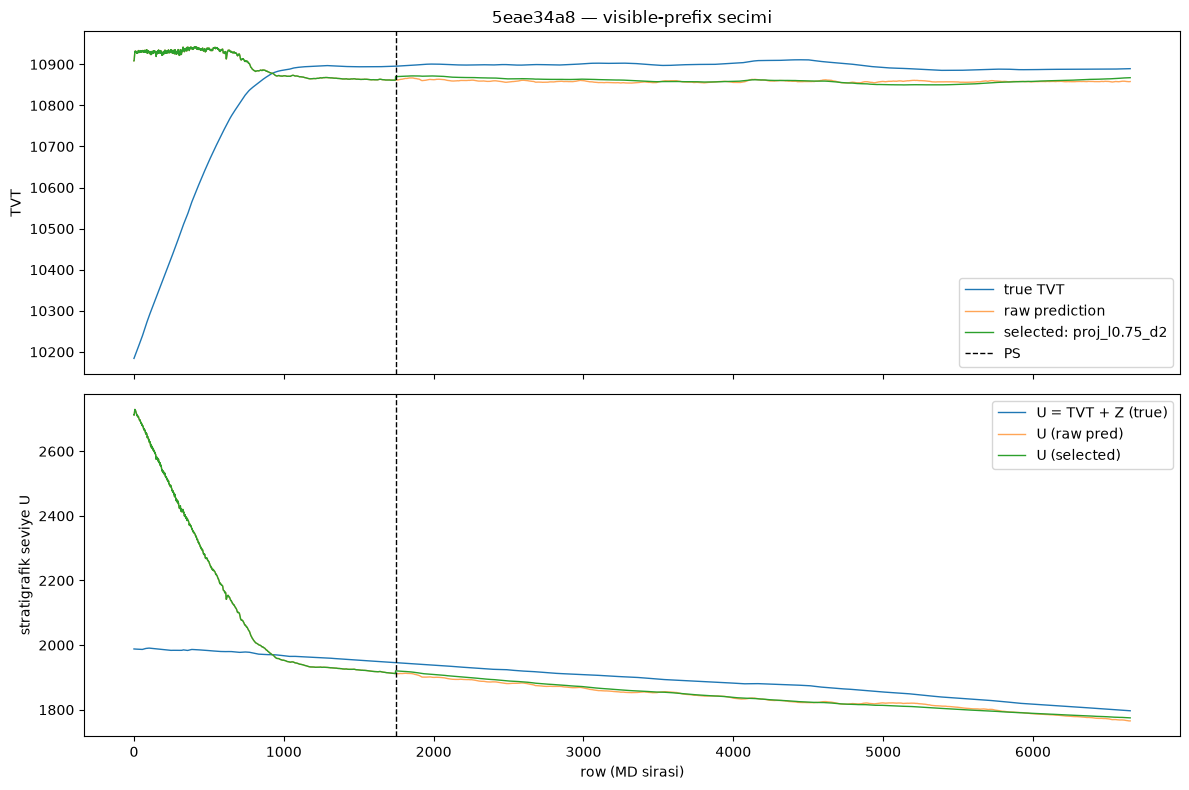

5eae34a8: raw RMSE 38.933 -> proj_l0.75_d2 RMSE 37.333


In [7]:
import matplotlib.pyplot as plt

# Ornek kuyu: raw tahmin vs secilen aday vs gercek TVT, ve U = TVT + Z
# seviyesinin projection'la nasil duzlestigi.

def _raw_well_rmse(r):
    ps = r["real_ps"]
    return float(np.sqrt(np.mean(
        (r["pred_real"][ps:] - r["true_tvt"][ps:]) ** 2
    )))


_well_id = max(valid_results, key=lambda wid: _raw_well_rmse(valid_results[wid]))
_r = valid_results[_well_id]
_ps = _r["real_ps"]
_selected = apply_candidate(
    _r["selected"], _r["pred_real"], _r["true_tvt"], _r["z_raw"], _ps
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(_r["true_tvt"], label="true TVT", lw=1)
axes[0].plot(_r["pred_real"], label="raw prediction", lw=1, alpha=0.7)
axes[0].plot(_selected, label=f"selected: {_r['selected']}", lw=1)
axes[0].axvline(_ps, color="k", ls="--", lw=1, label="PS")
axes[0].set_ylabel("TVT")
axes[0].set_title(f"{_well_id} — visible-prefix secimi")
axes[0].legend()

_u_true = _r["true_tvt"] + _r["z_raw"]
_u_raw = _r["pred_real"] + _r["z_raw"]
_u_sel = _selected + _r["z_raw"]
axes[1].plot(_u_true, label="U = TVT + Z (true)", lw=1)
axes[1].plot(_u_raw, label="U (raw pred)", lw=1, alpha=0.7)
axes[1].plot(_u_sel, label="U (selected)", lw=1)
axes[1].axvline(_ps, color="k", ls="--", lw=1)
axes[1].set_xlabel("row (MD sirasi)")
axes[1].set_ylabel("stratigrafik seviye U")
axes[1].legend()

plt.tight_layout()
plt.show()

_raw_rmse = float(np.sqrt(np.mean(
    (_r["pred_real"][_ps:] - _r["true_tvt"][_ps:]) ** 2
)))
_sel_rmse = float(np.sqrt(np.mean(
    (_selected[_ps:] - _r["true_tvt"][_ps:]) ** 2
)))
print(f"{_well_id}: raw RMSE {_raw_rmse:.3f} -> "
      f"{_r['selected']} RMSE {_sel_rmse:.3f}")